In [1]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/zeinebsinini/label-set-final/label_set_final.csv')
print(df.shape)
print(df.columns.tolist())
df.head()



(223, 11)
['id', 'class', 'layer', 'path', 'elev_1', 'slope_1', 'aspect_1', 'curvprof_1', 'curvplan_1', 'twi_1', 'tri_1']


,id,class,layer,path,elev_1,slope_1,aspect_1,curvprof_1,curvplan_1,twi_1,tri_1
0,0,0,points_negative_final,C:\Users\msi\Downloads\stage_sidi_bou\points_n...,116.523621,8.703588,191.754211,-0.003350,-0.002851,6.837533,12.891447
1,1,0,points_negative_final,C:\Users\msi\Downloads\stage_sidi_bou\points_n...,87.795227,19.033836,39.441528,-0.005706,-0.005938,6.487127,28.730934
2,4,0,points_negative_final,C:\Users\msi\Downloads\stage_sidi_bou\points_n...,129.387589,4.671224,112.602631,0.003415,0.005434,4.138447,11.527583
3,11,0,points_negative_final,C:\Users\msi\Downloads\stage_sidi_bou\points_n...,69.060440,3.085208,217.749069,0.000098,-0.003145,9.926003,5.964004
4,12,0,points_negative_final,C:\Users\msi\Downloads\stage_sidi_bou\points_n...,125.239243,9.028386,75.147575,0.002284,0.003538,4.206964,14.271803


In [2]:
import numpy as np

features = ['elev_1', 'slope_1', 'aspect_1', 'curvprof_1', 'curvplan_1', 'twi_1', 'tri_1']

fr_tables = {}

for feat in features:
    # bin into 5 quantile-based bins so each bin has a reasonable sample size
    df[f'{feat}_bin'] = pd.qcut(df[feat], q=5, duplicates='drop')
    
    total_counts = df.groupby(f'{feat}_bin', observed=True).size()
    positive_counts = df[df['class'] == 1].groupby(f'{feat}_bin', observed=True).size()
    
    pct_area = total_counts / total_counts.sum()
    pct_positive = positive_counts.reindex(total_counts.index, fill_value=0) / positive_counts.sum()
    
    fr = pct_positive / pct_area
    fr_tables[feat] = fr
    
    print(f"\n=== Frequency Ratio: {feat} ===")
    print(fr)


=== Frequency Ratio: elev_1 ===
elev_1_bin
(-0.001, 22.743]     1.017366
(22.743, 42.156]     1.241872
(42.156, 52.27]      1.444003
(52.27, 73.904]      1.050184
(73.904, 129.388]    0.234949
dtype: float64

=== Frequency Ratio: slope_1 ===
slope_1_bin
(0.56, 4.123]       1.017366
(4.123, 12.491]     0.469898
(12.491, 18.103]    1.017366
(18.103, 26.139]    1.107616
(26.139, 41.711]    1.378366
dtype: float64

=== Frequency Ratio: aspect_1 ===
aspect_1_bin
(1.1600000000000001, 57.32]    0.689183
(57.32, 217.448]               0.939795
(217.448, 263.753]             0.820456
(263.753, 285.494]             1.174744
(285.494, 359.293]             1.378366
dtype: float64

=== Frequency Ratio: curvprof_1 ===
curvprof_1_bin
(-0.0196, -0.00336]      1.083002
(-0.00336, -0.000968]    1.017366
(-0.000968, 0.000247]    1.083002
(0.000247, 0.00313]      0.789928
(0.00313, 0.014]         1.017366
dtype: float64

=== Frequency Ratio: curvplan_1 ===
curvplan_1_bin
(-0.024, -0.00239]       1.017366

In [3]:
# ============================================================
# RF susceptibility model — Sidi Bou Said
# Secondary/comparison method to the Frequency Ratio analysis
# ============================================================

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, confusion_matrix

features = ['elev_1', 'slope_1', 'aspect_1', 'curvprof_1', 'curvplan_1', 'twi_1', 'tri_1']
X = df[features].values
y = df['class'].values

# ---- Leave-One-Out cross-validation (appropriate given the small sample size) ----
loo = LeaveOneOut()
y_true_all = []
y_pred_proba_all = []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    clf = RandomForestClassifier(
        n_estimators=300,
        max_depth=5,          # kept shallow given the small sample, to limit overfitting
        min_samples_leaf=3,
        random_state=42,
        class_weight='balanced'  # compensates for the 151/72 class imbalance
    )
    clf.fit(X_train, y_train)

    proba = clf.predict_proba(X_test)[:, 1]
    y_pred_proba_all.append(proba[0])
    y_true_all.append(y_test[0])

y_true_all = np.array(y_true_all)
y_pred_proba_all = np.array(y_pred_proba_all)

# ---- AUC-ROC ----
auc = roc_auc_score(y_true_all, y_pred_proba_all)
print(f"AUC-ROC (leave-one-out): {auc:.3f}")

# ---- True Skill Statistic (TSS) at a 0.5 threshold ----
y_pred_class = (y_pred_proba_all >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true_all, y_pred_class).ravel()
sensitivity = tp / (tp + fn)   # true positive rate
specificity = tn / (tn + fp)   # true negative rate
tss = sensitivity + specificity - 1
print(f"Sensitivity: {sensitivity:.3f}")
print(f"Specificity: {specificity:.3f}")
print(f"TSS: {tss:.3f}")

# ---- Train one final model on ALL data, for feature importance ----
final_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=3,
    random_state=42,
    class_weight='balanced'
)
final_clf.fit(X, y)

importances = pd.Series(final_clf.feature_importances_, index=features).sort_values(ascending=False)
print("\n=== Feature importances (full-data RF) ===")
print(importances)


#----------------------------------------------------------------------------------------------------------
# ============================================================
# RF susceptibility model — Sidi Bou Said
# Secondary/comparison method to the Frequency Ratio analysis
# ============================================================

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, confusion_matrix

features = ['elev_1', 'slope_1', 'aspect_1', 'curvprof_1', 'curvplan_1', 'twi_1', 'tri_1']
X = df[features].values
y = df['class'].values

# ---- Leave-One-Out cross-validation (appropriate given the small sample size) ----
loo = LeaveOneOut()
y_true_all = []
y_pred_proba_all = []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    clf = RandomForestClassifier(
        n_estimators=300,
        max_depth=5,          # kept shallow given the small sample, to limit overfitting
        min_samples_leaf=3,
        random_state=42,
        class_weight='balanced'  # compensates for the 151/72 class imbalance
    )
    clf.fit(X_train, y_train)

    proba = clf.predict_proba(X_test)[:, 1]
    y_pred_proba_all.append(proba[0])
    y_true_all.append(y_test[0])

y_true_all = np.array(y_true_all)
y_pred_proba_all = np.array(y_pred_proba_all)

# ---- AUC-ROC ----
auc = roc_auc_score(y_true_all, y_pred_proba_all)
print(f"AUC-ROC (leave-one-out): {auc:.3f}")

# ---- True Skill Statistic (TSS) at a 0.5 threshold ----
y_pred_class = (y_pred_proba_all >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true_all, y_pred_class).ravel()
sensitivity = tp / (tp + fn)   # true positive rate
specificity = tn / (tn + fp)   # true negative rate
tss = sensitivity + specificity - 1
print(f"Sensitivity: {sensitivity:.3f}")
print(f"Specificity: {specificity:.3f}")
print(f"TSS: {tss:.3f}")

# ---- Train one final model on ALL data, for feature importance ----
final_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=3,
    random_state=42,
    class_weight='balanced'
)
final_clf.fit(X, y)

importances = pd.Series(final_clf.feature_importances_, index=features).sort_values(ascending=False)
print("\n=== Feature importances (full-data RF) ===")
print(importances)


# ============================================================
# Sensitivity check: rerun WITHOUT elevation
# Tests whether elevation was a spatial-clustering shortcut
# rather than a genuine terrain driver
# ============================================================

features_no_elev = ['slope_1', 'aspect_1', 'curvprof_1', 'curvplan_1', 'twi_1', 'tri_1']
X_ne = df[features_no_elev].values

y_true_ne = []
y_pred_proba_ne = []

for train_idx, test_idx in loo.split(X_ne):
    X_train, X_test = X_ne[train_idx], X_ne[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    clf_ne = RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42,
        class_weight='balanced'
    )
    clf_ne.fit(X_train, y_train)

    proba = clf_ne.predict_proba(X_test)[:, 1]
    y_pred_proba_ne.append(proba[0])
    y_true_ne.append(y_test[0])

y_true_ne = np.array(y_true_ne)
y_pred_proba_ne = np.array(y_pred_proba_ne)

auc_ne = roc_auc_score(y_true_ne, y_pred_proba_ne)
print(f"\n=== Without elevation ===")
print(f"AUC-ROC (leave-one-out): {auc_ne:.3f}")

y_pred_class_ne = (y_pred_proba_ne >= 0.5).astype(int)
tn_ne, fp_ne, fn_ne, tp_ne = confusion_matrix(y_true_ne, y_pred_class_ne).ravel()
sens_ne = tp_ne / (tp_ne + fn_ne)
spec_ne = tn_ne / (tn_ne + fp_ne)
tss_ne = sens_ne + spec_ne - 1
print(f"Sensitivity: {sens_ne:.3f}")
print(f"Specificity: {spec_ne:.3f}")
print(f"TSS: {tss_ne:.3f}")

final_clf_ne = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=3,
    random_state=42,
    class_weight='balanced'
)
final_clf_ne.fit(X_ne, y)

importances_ne = pd.Series(final_clf_ne.feature_importances_, index=features_no_elev).sort_values(ascending=False)
print("\n=== Feature importances WITHOUT elevation ===")
print(importances_ne)

AUC-ROC (leave-one-out): 0.958
Sensitivity: 0.940
Specificity: 0.833
TSS: 0.774

=== Feature importances (full-data RF) ===
elev_1        0.365717
aspect_1      0.182388
tri_1         0.142333
slope_1       0.135869
twi_1         0.079725
curvplan_1    0.049737
curvprof_1    0.044231
dtype: float64
AUC-ROC (leave-one-out): 0.958
Sensitivity: 0.940
Specificity: 0.833
TSS: 0.774

=== Feature importances (full-data RF) ===
elev_1        0.365717
aspect_1      0.182388
tri_1         0.142333
slope_1       0.135869
twi_1         0.079725
curvplan_1    0.049737
curvprof_1    0.044231
dtype: float64

=== Without elevation ===
AUC-ROC (leave-one-out): 0.884
Sensitivity: 0.781
Specificity: 0.819
TSS: 0.601

=== Feature importances WITHOUT elevation ===
aspect_1      0.295114
tri_1         0.252090
slope_1       0.237796
curvplan_1    0.084468
twi_1         0.076773
curvprof_1    0.053759
dtype: float64


Saved susceptibility_map_rf.tif
Value range: 0.021 to 0.999


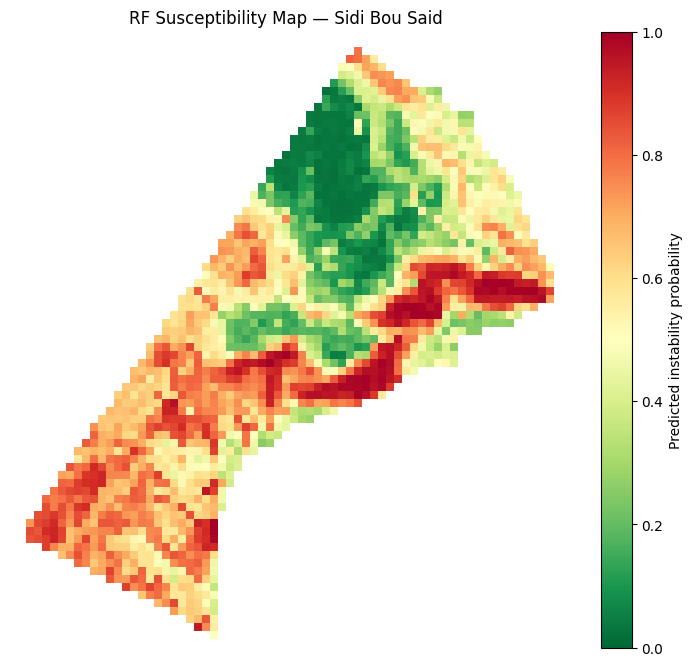

In [4]:
# ============================================================
# Generate the susceptibility map: apply the trained RF model
# to every pixel of the AOI's terrain rasters
# ============================================================

import rasterio
import numpy as np

# ---- Update this path to match your uploaded dataset folder ----
RASTER_DIR = '/kaggle/input/datasets/zeinebsinini/sidi-bou-v3/'

raster_files = {
    'elev_1': RASTER_DIR + 'sidi_bou_said_dem_v3.tif',
    'slope_1': RASTER_DIR + 'terrain_slope_v3.tif',
    'aspect_1': RASTER_DIR + 'terrain_aspect_v3.tif',
    'curvprof_1': RASTER_DIR + 'terrain_profile_curvature_v3.tif',
    'curvplan_1': RASTER_DIR + 'terrain_tengential_curvature_v3.tif',
    'twi_1': RASTER_DIR + 'terrain_twi_v3.tif',
    'tri_1': RASTER_DIR + 'terrain_tri_v3.tif',
}

# Keep the SAME feature order used to train final_clf
feature_order = ['elev_1', 'slope_1', 'aspect_1', 'curvprof_1', 'curvplan_1', 'twi_1', 'tri_1']

# ---- Load all rasters, using the DEM as the reference grid ----
with rasterio.open(raster_files['elev_1']) as ref:
    ref_profile = ref.profile
    ref_shape = ref.shape
    ref_transform = ref.transform

stacked = np.zeros((len(feature_order), ref_shape[0], ref_shape[1]), dtype=np.float32)
nodata_mask = np.zeros(ref_shape, dtype=bool)

for i, feat in enumerate(feature_order):
    with rasterio.open(raster_files[feat]) as src:
        band = src.read(
            1,
            out_shape=ref_shape,
            resampling=rasterio.enums.Resampling.bilinear
        ).astype(np.float32)
        stacked[i] = band
        # flag nodata / NaN pixels so we can mask them out of the prediction
        if src.nodata is not None:
            nodata_mask |= (band == src.nodata)
        nodata_mask |= np.isnan(band)

# ---- Reshape to (n_pixels, n_features) for prediction ----
n_features, height, width = stacked.shape
X_pixels = stacked.reshape(n_features, -1).T  # shape: (height*width, n_features)
valid_mask = ~nodata_mask.reshape(-1)

# ---- Predict probability of instability for valid pixels only ----
susceptibility = np.full(X_pixels.shape[0], np.nan, dtype=np.float32)
susceptibility[valid_mask] = final_clf.predict_proba(X_pixels[valid_mask])[:, 1]

# ---- Reshape back to a 2D raster ----
susceptibility_map = susceptibility.reshape(height, width)

# ---- Save as GeoTIFF ----
out_profile = ref_profile.copy()
out_profile.update(dtype=rasterio.float32, count=1, nodata=np.nan)

with rasterio.open('/kaggle/working/susceptibility_map_rf.tif', 'w', **out_profile) as dst:
    dst.write(susceptibility_map, 1)

print("Saved susceptibility_map_rf.tif")
print(f"Value range: {np.nanmin(susceptibility_map):.3f} to {np.nanmax(susceptibility_map):.3f}")

# ---- Quick visual check ----
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))
plt.imshow(susceptibility_map, cmap='RdYlGn_r', vmin=0, vmax=1)
plt.colorbar(label='Predicted instability probability')
plt.title('RF Susceptibility Map — Sidi Bou Said')
plt.axis('off')
plt.savefig('/kaggle/working/susceptibility_map_preview.png', dpi=150, bbox_inches='tight')
plt.show()

Saved susceptibility_map_fr.tif
Raw combined FR range: 0.019 to 5.297


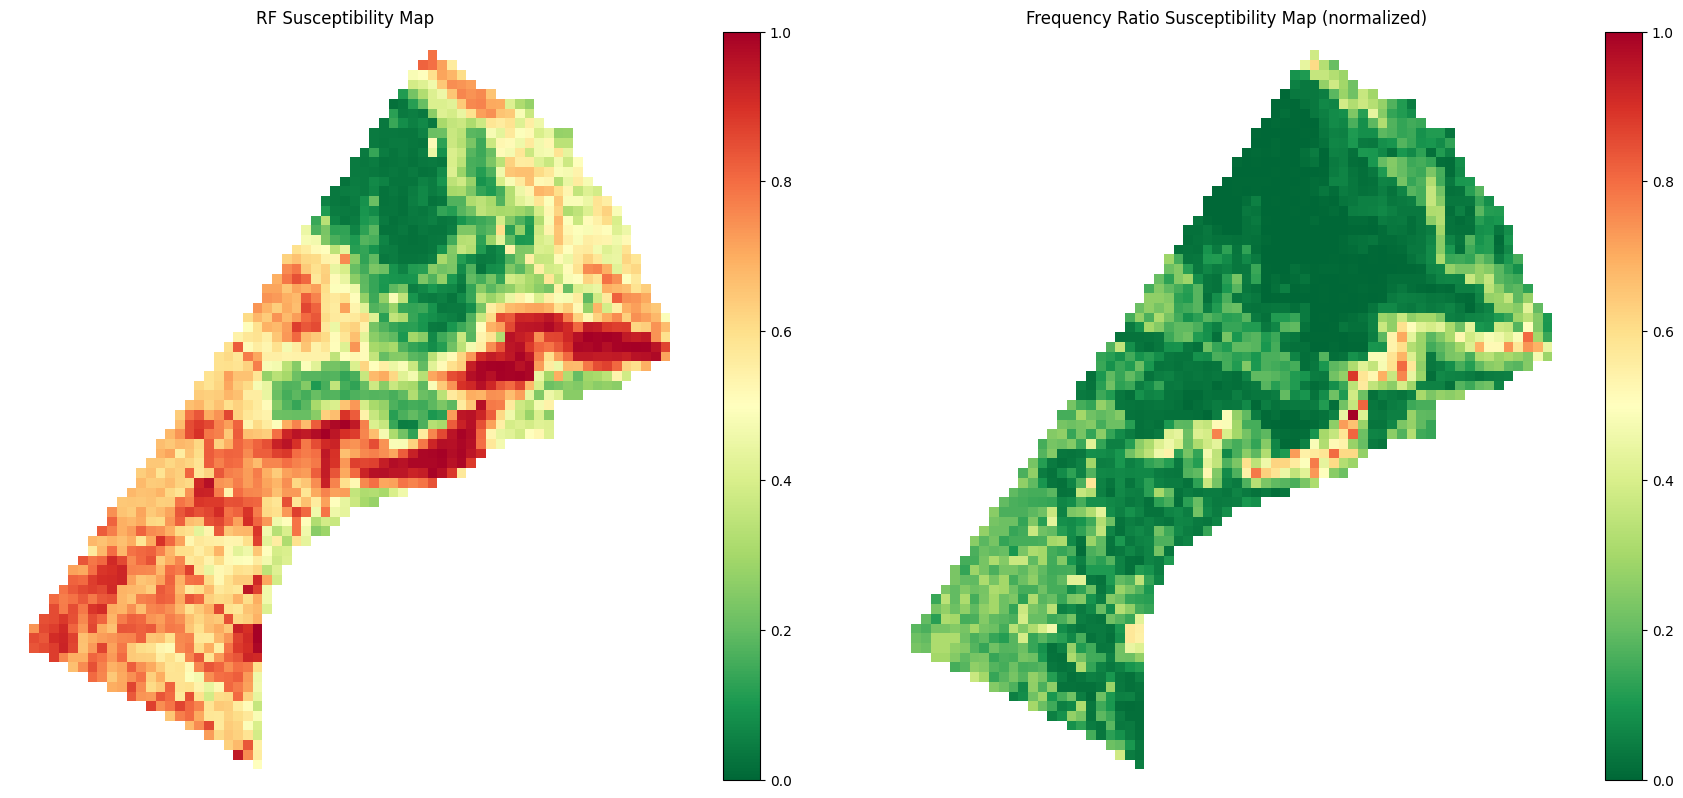

In [5]:
# ============================================================
# Frequency Ratio susceptibility map — per pixel
# Uses the SAME bin edges as the earlier FR analysis on df,
# so it's directly comparable to the RF map.
# ============================================================

import pandas as pd
import numpy as np

features = ['elev_1', 'slope_1', 'aspect_1', 'curvprof_1', 'curvplan_1', 'twi_1', 'tri_1']

# ---- Recompute FR tables, this time keeping the actual bin edges ----
fr_lookup = {}      # feature -> (bin_edges array, FR values per bin)

for feat in features:
    binned, bin_edges = pd.qcut(df[feat], q=5, duplicates='drop', retbins=True)
    df[f'{feat}_bin'] = binned

    total_counts = df.groupby(f'{feat}_bin', observed=True).size()
    positive_counts = df[df['class'] == 1].groupby(f'{feat}_bin', observed=True).size()

    pct_area = total_counts / total_counts.sum()
    pct_positive = positive_counts.reindex(total_counts.index, fill_value=0) / positive_counts.sum()
    fr = (pct_positive / pct_area).values  # in the same order as the bin categories

    fr_lookup[feat] = (bin_edges, fr)

# ---- Apply these bins + FR values to every pixel in the raster stack ----
# `stacked` (shape: n_features, height, width) and `feature_order` should
# already exist from the susceptibility-map script; if not, rerun that
# loading section first.

fr_per_feature = np.ones((len(feature_order), height, width), dtype=np.float32)

for i, feat in enumerate(feature_order):
    bin_edges, fr_values = fr_lookup[feat]
    pixel_values = stacked[i]

    # np.digitize assigns each pixel to a bin index based on the training edges
    # clip to valid range so values outside the training range fall into the
    # nearest edge bin rather than erroring
    bin_idx = np.digitize(pixel_values, bin_edges[1:-1], right=True)
    bin_idx = np.clip(bin_idx, 0, len(fr_values) - 1)

    fr_per_feature[i] = fr_values[bin_idx]

# ---- Combine: multiply FR values across all features ----
# (a pixel that scores high FR on multiple independent features gets a
# compounded high score — standard multi-factor FR overlay approach)
fr_combined = np.prod(fr_per_feature, axis=0)
fr_combined[nodata_mask] = np.nan

# ---- Normalize to 0-1 for easier visual comparison against the RF map ----
valid_vals = fr_combined[~nodata_mask]
fr_normalized = (fr_combined - np.nanmin(valid_vals)) / (np.nanmax(valid_vals) - np.nanmin(valid_vals))

# ---- Save as GeoTIFF ----
out_profile_fr = ref_profile.copy()
out_profile_fr.update(dtype=rasterio.float32, count=1, nodata=np.nan)

with rasterio.open('/kaggle/working/susceptibility_map_fr.tif', 'w', **out_profile_fr) as dst:
    dst.write(fr_normalized.astype(np.float32), 1)

print("Saved susceptibility_map_fr.tif")
print(f"Raw combined FR range: {np.nanmin(fr_combined):.3f} to {np.nanmax(fr_combined):.3f}")

# ---- Visual comparison: RF vs FR side by side ----
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

im0 = axes[0].imshow(susceptibility_map, cmap='RdYlGn_r', vmin=0, vmax=1)
axes[0].set_title('RF Susceptibility Map')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(fr_normalized, cmap='RdYlGn_r', vmin=0, vmax=1)
axes[1].set_title('Frequency Ratio Susceptibility Map (normalized)')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.savefig('/kaggle/working/rf_vs_fr_comparison.png', dpi=150, bbox_inches='tight')
plt.show()